# Full phase curve: thermal + reflected

`full_PhaseCurve` sums the thermal (`02_thermal_phase_curve.ipynb`) and reflected (`03_reflected_phase_curve.ipynb`) phase curves. The components for the extended star (`"hyperillum"`) and the point source (`"naive"`), and their difference between the two models.

In [1]:
import matplotlib.pyplot as plt
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman
from hyperphase.model import ConstantBandAlbedo
from hyperphase.phasecurve import full_PhaseCurve, reflected_PhaseCurve, thermal_PhaseCurve
from hyperphase.bands import filter_lambda, filter_loc
from hyperphase.defaults import DEFAULT_A, DEFAULT_A_B, DEFAULT_U, DEFAULT_U_BOL
from hyperphase.targets import hi_planets_by_name

In [2]:
planet = hi_planets_by_name("TOI-2431 b")   # an archive planet or a curated entry (inputs/planets/curated_planets.csv)
u, u_bol = DEFAULT_U, DEFAULT_U_BOL       # transit and irradiance limb darkening
A_B = DEFAULT_A_B                         # Bond albedo: sets the temperature map
A_model = ConstantBandAlbedo(DEFAULT_A)   # band albedo A of the reflected light, independent of A_B
A = A_model(A_B)

Instrument = "MIRI/LRS"
lambda_range, filter_path = filter_lambda(Instrument), filter_loc(Instrument)

## 1. Components

Full, thermal and reflected phase curve of each model, with the occultation depths.

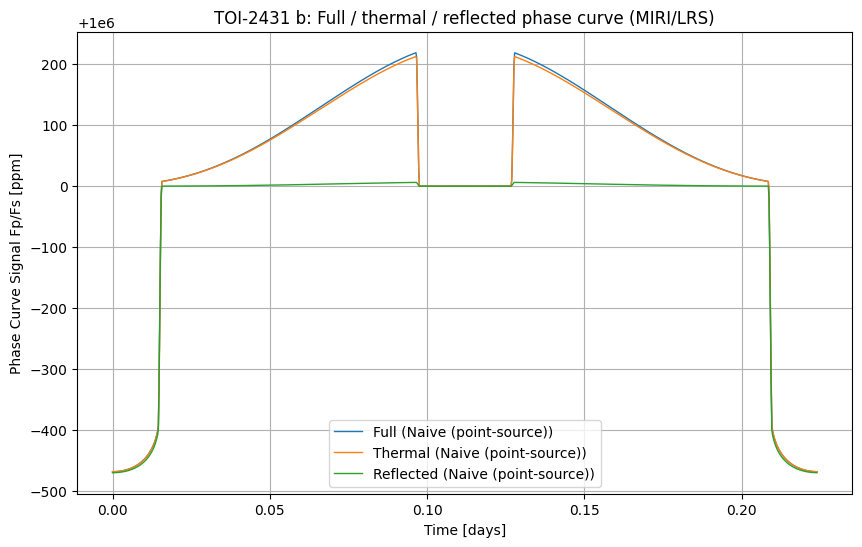

Naive (point-source)   occultation depth:  full= 234.9  thermal= 228.1  reflected=   6.7  ppm


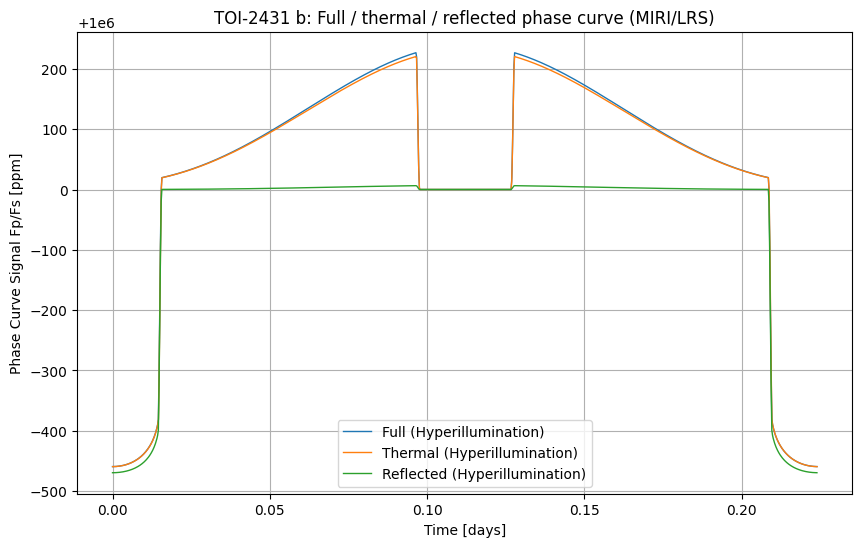

Hyperillumination      occultation depth:  full= 239.2  thermal= 232.3  reflected=   6.9  ppm


In [3]:
for model, mlabel in [("naive", "Naive (point-source)"), ("hyperillum", "Hyperillumination")]:
    t_full,  full_pc,  fp_full     = full_PhaseCurve(planet, lambda_range, u=u, A=A, A_B=A_B, filter_path=filter_path, insolation_model=model, u_bol=u_bol)
    t_therm, therm_pc, fp_therm, _ = thermal_PhaseCurve(planet, lambda_range, u=u, A_B=A_B, filter_path=filter_path, insolation_model=model, u_bol=u_bol)
    t_refl,  refl_pc,  fp_refl     = reflected_PhaseCurve(planet, u=u, A=A, insolation_model=model, u_bol=u_bol)
    
    plt.figure(figsize=(10, 6))
    plt.plot(t_full,  full_pc*1e6, color="C0", linewidth=1, label=f"Full ({mlabel})")
    plt.plot(t_therm, therm_pc*1e6, color="C1", linewidth=1, label=f"Thermal ({mlabel})")
    plt.plot(t_refl,  refl_pc*1e6, color="C2", linewidth=1, label=f"Reflected ({mlabel})")
    plt.xlabel("Time [days]")
    plt.ylabel(r"Phase Curve Signal Fp/Fs [ppm]")
    plt.title(f"{planet.name}: Full / thermal / reflected phase curve ({Instrument})")
    plt.legend()
    plt.grid()
    plt.show()
    print(f"{mlabel:22s} occultation depth:  full={fp_full:6.1f}  thermal={fp_therm:6.1f}  reflected={fp_refl:6.1f}  ppm")

## 2. Extended minus point source

The difference of each component between the two models, as computed (top) and with each curve's own mean removed (bottom), since a fit absorbs a constant offset.

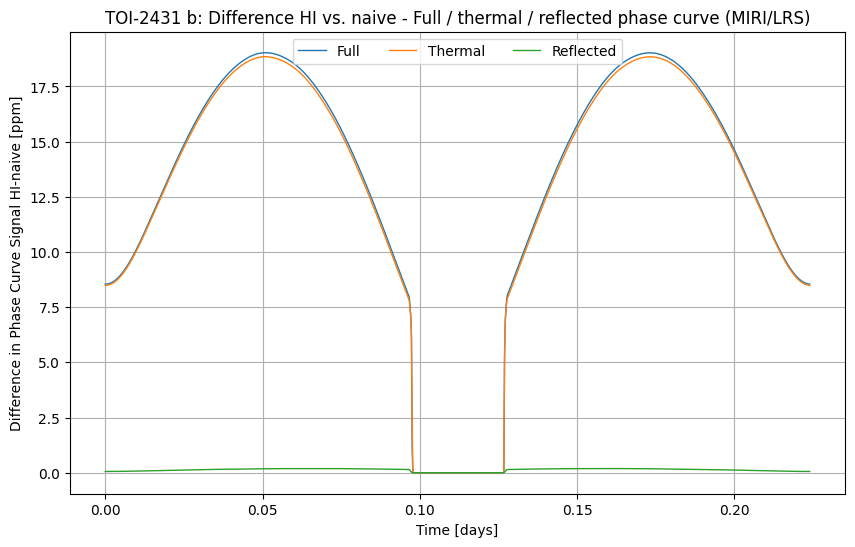

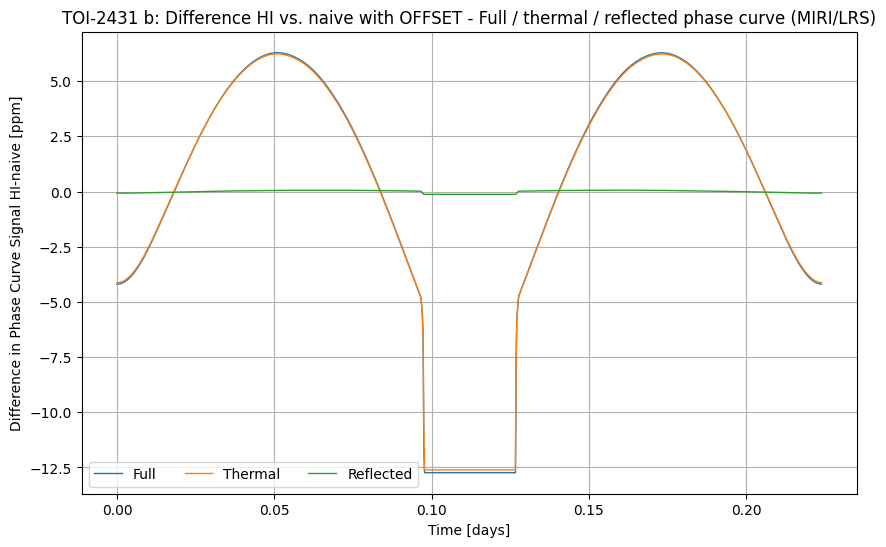

In [4]:
t_full1,  full_pc1,  fp_full1     = full_PhaseCurve(planet, lambda_range, u=u, A=A, A_B=A_B, filter_path=filter_path, insolation_model="naive", u_bol=u_bol)
t_therm1, therm_pc1, fp_therm1, _ = thermal_PhaseCurve(planet, lambda_range, u=u, A_B=A_B, filter_path=filter_path, insolation_model="naive", u_bol=u_bol)
t_refl1,  refl_pc1,  fp_refl1     = reflected_PhaseCurve(planet, u=u, A=A, insolation_model="naive", u_bol=u_bol)
t_full2,  full_pc2,  fp_full2     = full_PhaseCurve(planet, lambda_range, u=u, A=A, A_B=A_B, filter_path=filter_path, insolation_model="hyperillum", u_bol=u_bol)
t_therm2, therm_pc2, fp_therm2, _ = thermal_PhaseCurve(planet, lambda_range, u=u, A_B=A_B, filter_path=filter_path, insolation_model="hyperillum", u_bol=u_bol)
t_refl2,  refl_pc2,  fp_refl2     = reflected_PhaseCurve(planet, u=u, A=A, insolation_model="hyperillum", u_bol=u_bol)

plt.figure(figsize=(10, 6))
plt.plot(t_full1,  (full_pc2 - full_pc1)*1e6, color="C0", linewidth=1, label=f"Full")
plt.plot(t_therm1, (therm_pc2 - therm_pc1)*1e6, color="C1", linewidth=1, label=f"Thermal")
plt.plot(t_refl1,  (refl_pc2 - refl_pc1)*1e6, color="C2", linewidth=1, label=f"Reflected")
plt.xlabel("Time [days]")
plt.ylabel(r"Difference in Phase Curve Signal HI-naive [ppm]")
plt.title(f"{planet.name}: Difference HI vs. naive - Full / thermal / reflected phase curve ({Instrument})")
plt.legend(ncol=3)
plt.grid()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t_full1,  ((full_pc2-full_pc2.mean()) - (full_pc1-full_pc1.mean()))*1e6, color="C0", linewidth=1, label=f"Full")
plt.plot(t_therm1, ((therm_pc2-therm_pc2.mean()) - (therm_pc1-therm_pc1.mean()))*1e6, color="C1", linewidth=1, label=f"Thermal")
plt.plot(t_refl1,  ((refl_pc2-refl_pc2.mean()) - (refl_pc1-refl_pc1.mean()))*1e6, color="C2", linewidth=1, label=f"Reflected")
plt.xlabel("Time [days]")
plt.ylabel(r"Difference in Phase Curve Signal HI-naive [ppm]")
plt.title(f"{planet.name}: Difference HI vs. naive with OFFSET - Full / thermal / reflected phase curve ({Instrument})")
plt.legend(ncol=3)
plt.grid()
plt.show()